In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path
from datetime import timedelta, timezone

src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))


from sciezka_projektu import get_project_root

PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Rybnik"

df_r_pz1 = pd.read_parquet(DATA_PATH / "pz1-2024.parquet")

df_rs_opady = pd.read_parquet(DATA_PATH / "suma_opadow.parquet")




In [19]:
%load_ext autoreload
%autoreload 2

from models.final.przepompowanie_rybnik_dane import przygotuj_dane_przepompowanie

X_pz1,y_pz1, X_pnb1, y_pnb1 = przygotuj_dane_przepompowanie()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
%load_ext autoreload
%autoreload 2
X = X_pnb1
y = y_pnb1

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
y

Data_czas
2024-01-07 01:00:00+01:00    10.0
2024-01-07 02:00:00+01:00     8.0
2024-01-07 03:00:00+01:00    11.0
2024-01-07 04:00:00+01:00     7.0
2024-01-07 05:00:00+01:00     9.0
                             ... 
2026-09-28 08:00:00+01:00     9.0
2026-09-28 09:00:00+01:00    10.0
2026-09-28 10:00:00+01:00     8.0
2026-09-28 11:00:00+01:00    11.0
2026-09-28 12:00:00+01:00     8.0
Name: przepompowano_m3, Length: 23856, dtype: float64

In [21]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 1470 z 7157


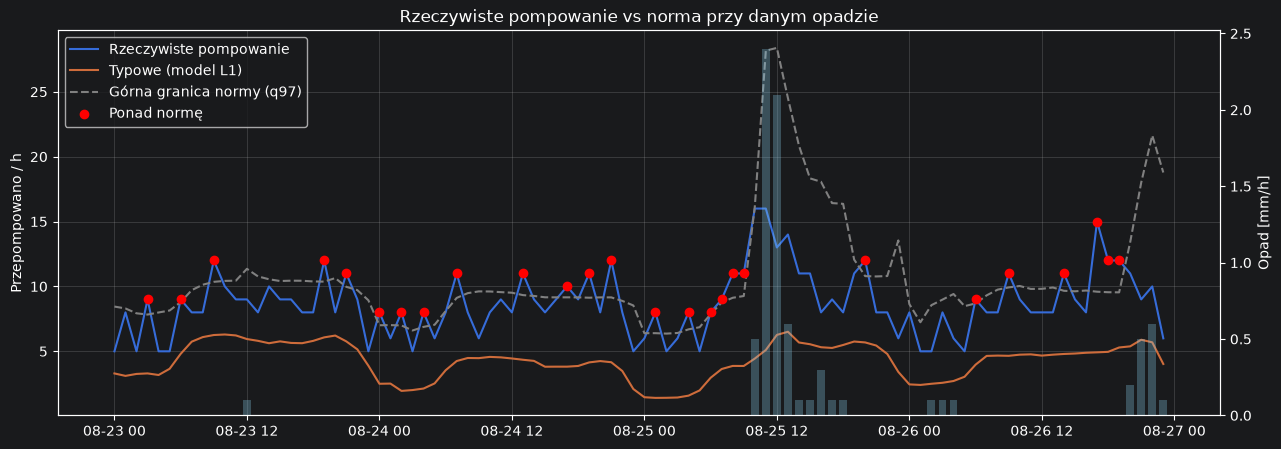

In [27]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-08-23":"2026-08-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [28]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 1470
Suma nadwyżek w godzinach alarmowych: 6339.23


In [29]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2025-12-03 19:00:00+01:00,11.0,8.364859,10.889270,2.635141,0.110730,0.0,0.2
2025-12-03 20:00:00+01:00,11.0,8.499684,10.933889,2.500316,0.066111,0.0,0.1
2025-12-03 21:00:00+01:00,11.0,8.394752,10.969134,2.605248,0.030866,0.0,0.0
2025-12-03 23:00:00+01:00,11.0,7.060942,10.563350,3.939058,0.436650,0.0,0.0
2025-12-04 00:00:00+01:00,8.0,6.139628,7.813892,1.860372,0.186108,0.0,0.0
...,...,...,...,...,...,...,...
2026-09-27 16:00:00+01:00,11.0,4.941265,10.984840,6.058735,0.015160,0.0,0.0
2026-09-27 19:00:00+01:00,13.0,5.169988,10.999438,7.830012,2.000562,0.0,0.0
2026-09-28 00:00:00+01:00,8.0,2.246669,7.676224,5.753331,0.323776,0.0,0.0


In [30]:
from sklearn.metrics import mean_absolute_error
# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 2.49
MAE baseline: 2.22
Przekroczenia Q97 TEST: 20.54 %
Liczba alarmów TEST: 1470


In [31]:
#SHAP
from SHAP import generate_shap_from_tree

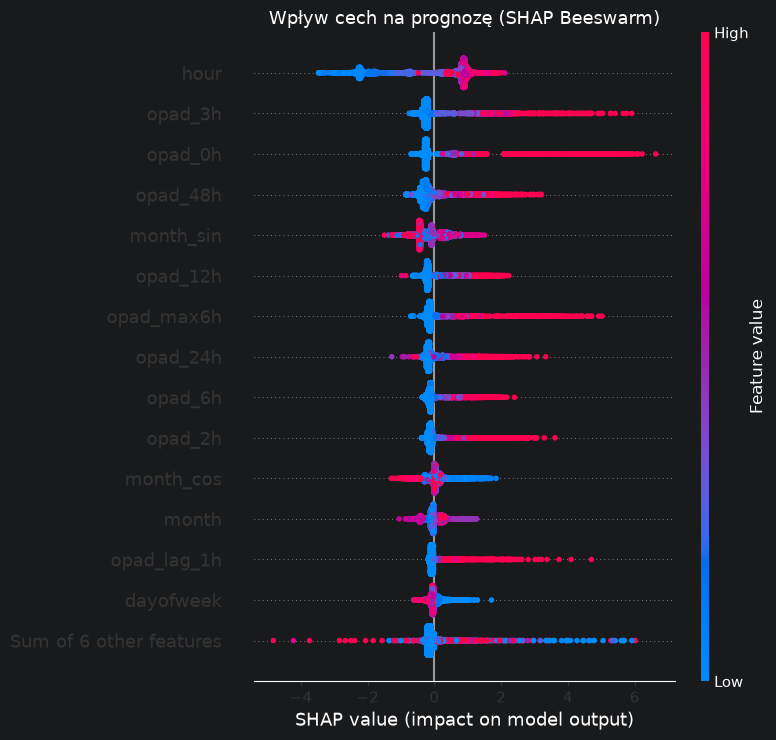

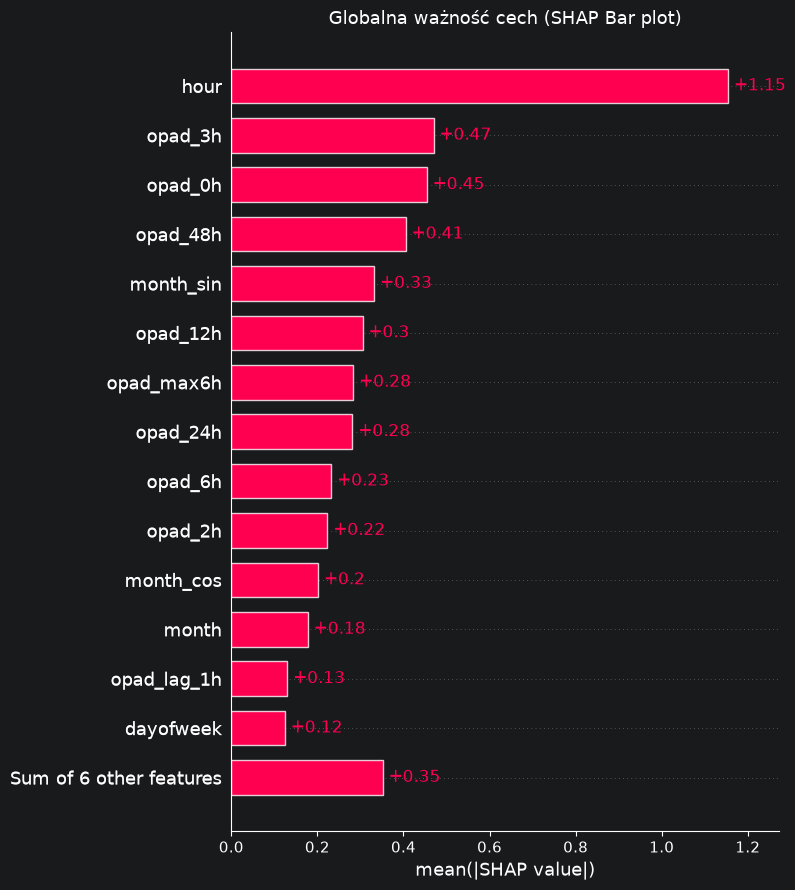

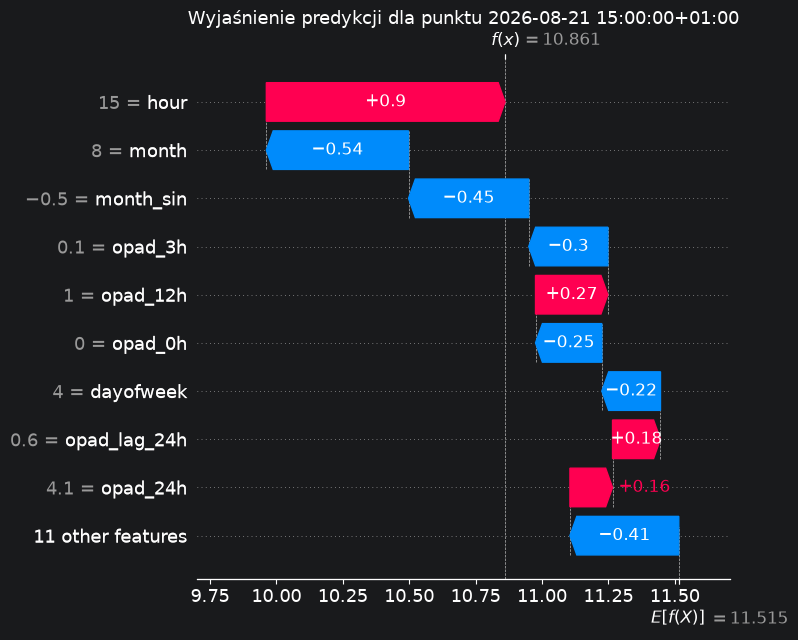

In [34]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2026-08-21 15:00:00")

# OPTYMALIZACJA OPTUNA

In [ ]:

import optuna

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

import numpy as np
import optuna


# STROJENIE MODELU MEDIANOWEGO (cb_median)
def objective_median(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    preds = model.predict(X_val)
    mae = np.mean(np.abs(y_val - preds))
    return mae

study_median = optuna.create_study(direction="minimize")
study_median.optimize(objective_median, n_trials=40)
print("Najlepsze parametry dla Median:", study_median.best_params)


# STROJENIE MODELU KWANTYLOWEGO (cb_q97)
def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        'loss_function': 'Quantile:alpha=0.97',
        'eval_metric': 'Quantile:alpha=0.97',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    q_preds = model.predict(X_val)

    #Błąd Pinball
    loss = pinball_loss(y_val, q_preds, alpha=0.97)

    #Kara za uciekanie od Coverage = 97%
    empirical_coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(empirical_coverage - 0.97) * 5.0

    return loss + coverage_penalty

study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print("Najlepsze parametry dla Q97:", study_q97.best_params)

[I 2026-10-28 13:07:47,249] A new study created in memory with name: no-name-6979d334-7439-4455-a9e2-8b9819360e33
[I 2026-10-28 13:07:49,116] Trial 0 finished with value: 1.691697933035638 and parameters: {'learning_rate': 0.024070346659893556, 'depth': 6, 'l2_leaf_reg': 10.35223179473093, 'random_strength': 1.5612769769949348}. Best is trial 0 with value: 1.691697933035638.
[I 2026-10-28 13:07:50,430] Trial 1 finished with value: 1.721564252783553 and parameters: {'learning_rate': 0.017421655354852864, 'depth': 5, 'l2_leaf_reg': 2.8946013322716957, 'random_strength': 2.503352616435724}. Best is trial 0 with value: 1.691697933035638.
[I 2026-10-28 13:07:55,495] Trial 2 finished with value: 1.68831558618824 and parameters: {'learning_rate': 0.01406844365930284, 'depth': 6, 'l2_leaf_reg': 14.557681657346594, 'random_strength': 4.014290510937217}. Best is trial 2 with value: 1.68831558618824.
[I 2026-10-28 13:08:00,591] Trial 3 finished with value: 1.694638005874135 and parameters: {'lear

In [12]:
print("Najlepszy wynik median (MAE):", study_median.best_value)
print("Najlepsze parametry median:", study_median.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 1.4846626321949579
Najlepsze parametry median: {'learning_rate': 0.04203513948641982, 'depth': 6, 'l2_leaf_reg': 19.838135683506707, 'random_strength': 1.7287450778554834}
Najlepszy wynik q97 (MAE): 0.13614742565953253
Najlepsze parametry q97: {'learning_rate': 0.013079619314708114, 'depth': 6, 'l2_leaf_reg': 11.689680625188423, 'random_strength': 0.48731610238448314}


In [13]:
# CATBOOST
from catboost import CatBoostRegressor


check_median = CatBoostRegressor(
    **study_median.best_params,
    loss_function="MAE",
    eval_metric="MAE",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=100
)
check_median.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True
)


best_trees = check_median.get_best_iteration()
print(f"Optymalna liczba iteracji: {best_trees}")

0:	learn: 2.6461371	test: 2.0325755	best: 2.0325755 (0)	total: 5.02ms	remaining: 12.6s
100:	learn: 1.8884530	test: 1.5179031	best: 1.5179031 (100)	total: 318ms	remaining: 7.56s
200:	learn: 1.7704871	test: 1.4938711	best: 1.4932800 (190)	total: 631ms	remaining: 7.22s
300:	learn: 1.6626086	test: 1.4889324	best: 1.4846616 (266)	total: 943ms	remaining: 6.89s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 1.484661632
bestIteration = 266

Shrink model to first 267 iterations.
Optymalna liczba iteracji: 266


In [14]:
from catboost import CatBoostRegressor


check_q97 = CatBoostRegressor(
    **study_q97.best_params,
    loss_function="Quantile:alpha=0.97",
    eval_metric="Quantile:alpha=0.97",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=0
)

check_q97.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True)

best_trees_q97 = check_q97.get_best_iteration()
q_test = check_q97.predict(X_test)
print(f"Optymalna liczba iteracji dla q97 to: {best_trees_q97}")
odsetek_test = np.mean(y_test.to_numpy() > q_test.ravel()) * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")

Optymalna liczba iteracji dla q97 to: 240
MAE TEST: 1.62
MAE baseline: 2.82
Przekroczenia Q97 TEST: 4.46 %
